# Function Visualization

Notebook tạo các interactive visualization (Plotly) và export thành HTML độc lập cho GitHub Pages.

> 📊 GitHub chỉ hiển thị **ảnh tĩnh** của biểu đồ (GitHub không chạy JavaScript). Xem bản **tương tác**: [Hàm số bậc nhất](https://tlh222k.github.io/ai-from-scratch/visualizations/linear_function.html) · [Hàm số bậc hai](https://tlh222k.github.io/ai-from-scratch/visualizations/quadratic_function.html) · [Giới hạn của hàm số](https://tlh222k.github.io/ai-from-scratch/visualizations/limit_function.html) · [Giới hạn khi x tiến đến 3](https://tlh222k.github.io/ai-from-scratch/visualizations/limit_approach_function.html) · [Đường cát tuyến](https://tlh222k.github.io/ai-from-scratch/visualizations/secant_line_function.html) · [Cát tuyến → tiếp tuyến (animation)](https://tlh222k.github.io/ai-from-scratch/visualizations/secant_to_tangent_function.html)

**Chạy bằng `Restart Kernel → Run All`.** Output: `visualizations/linear_function.html`, `quadratic_function.html`, `index.html`.

# Nhập thư viện

In [1]:
import sys
import numpy as np
import plotly
import plotly.graph_objects as go
import plotly.io as pio

from pathlib import Path
from IPython.display import display, HTML

print("=" * 50)
print("FUNCTION VISUALIZATION")
print("=" * 50)

print(f"Python: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")
print(f"NumPy: {np.__version__}")
print(f"Plotly: {plotly.__version__}")

FUNCTION VISUALIZATION
Python: 3.13.9
Python executable: d:\lh222k\ai-from-scratch\.venv\Scripts\python.exe
NumPy: 2.5.4
Plotly: 7.1.0


# Cấu hình dự án

In [2]:
def find_project_root(start_path=None):
    """
    Find the root directory of ai-from-scratch.

    The project root must contain:
        - phases/
        - visualizations/
    """

    current_path = Path(start_path or Path.cwd()).resolve()

    for path in [current_path, *current_path.parents]:

        has_phases = (path / "phases").is_dir()
        has_visualizations = (path / "visualizations").is_dir()

        if has_phases and has_visualizations:
            return path

    raise FileNotFoundError(
        "Cannot find project root. "
        "Expected 'phases/' and 'visualizations/' directories."
    )


# Detect project root
PROJECT_ROOT = find_project_root()

# Define directories
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"

NOTEBOOK_DIR = VISUALIZATION_DIR / "notebooks"

# Create directories if they do not exist
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)


print("Project root:", PROJECT_ROOT)
print("Visualization directory:", VISUALIZATION_DIR)
print("Notebook directory:", NOTEBOOK_DIR)

Project root: D:\lh222k\ai-from-scratch
Visualization directory: D:\lh222k\ai-from-scratch\visualizations
Notebook directory: D:\lh222k\ai-from-scratch\visualizations\notebooks


# Cấu hình hiển thị (Jupyter + GitHub)

Output gồm **cả hai**: `application/vnd.plotly.v1+json` (tương tác trong Jupyter/VS Code) và `image/png` (ảnh tĩnh để GitHub hiển thị). Cần `pip install kaleido`.

In [3]:
# Interactive in Jupyter/VS Code + static PNG fallback for GitHub
pio.renderers.default = "plotly_mimetype+png"

GITHUB_USER = "tlh222k"
REPO_NAME = "ai-from-scratch"

PAGES_BASE = f"https://{GITHUB_USER}.github.io/{REPO_NAME}/visualizations"

print("Renderer:", pio.renderers.default)
print("Pages base URL:", PAGES_BASE)

Renderer: plotly_mimetype+png
Pages base URL: https://tlh222k.github.io/ai-from-scratch/visualizations


# Hàm cấu hình biểu đồ dùng chung

Chỉ định nghĩa **một** lần `configure_figure()` (bản đầy đủ tham số). Trước đây hàm này bị định nghĩa hai lần nên bản thứ hai (thiếu `xaxis_title`, `yaxis_title`) ghi đè bản đầu.

In [4]:
def configure_figure(
    fig,
    title,
    xaxis_title="x",
    yaxis_title="y",
    height=520
):
    """
    Configure common Plotly figure settings.

    Parameters
    ----------
    fig : go.Figure
        Plotly figure.

    title : str
        Figure title.

    xaxis_title : str
        X-axis label.

    yaxis_title : str
        Y-axis label.

    height : int
        Figure height in pixels.
    """

    fig.update_layout(
        title={
            "text": title,
            "x": 0.5,
            "xanchor": "center",
            "font": {
                "size": 22
            }
        },

        autosize=True,
        height=height,

        margin=dict(
            l=60,
            r=30,
            t=110,   # room for title + horizontal legend
            b=60
        ),

        template="plotly_white",

        font=dict(
            family="Arial, sans-serif",
            size=14
        ),

        hovermode="closest",

        xaxis_title=xaxis_title,
        yaxis_title=yaxis_title,

        xaxis=dict(
            showgrid=True,
            zeroline=True,
            zerolinewidth=2,
            zerolinecolor="#64748b"
        ),

        yaxis=dict(
            showgrid=True,
            zeroline=True,
            zerolinewidth=2,
            zerolinecolor="#64748b"
        ),

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="center",
            x=0.5
        )
    )

    return fig

# Hàm tạo chú thích (caption) dùng chung

In [5]:
def build_caption_html(
    caption,
    title=None,
    font_size="16px"
):
    """
    Generate reusable HTML caption.

    The caption accepts trusted HTML and LaTeX.
    """

    title_html = ""

    if title:

        title_html = f"""
        <h3 class="caption-title">
            {title}
        </h3>
        """

    return f"""
    <div class="visualization-caption">

        {title_html}

        <div class="caption-content">
            {caption}
        </div>

    </div>

    <style>

        .visualization-caption {{
            width: 100%;
            box-sizing: border-box;

            margin-top: 16px;
            padding: 18px 22px;

            background: #f8fafc;

            border-left: 4px solid #2563eb;
            border-radius: 8px;

            font-size: {font_size};
            line-height: 1.8;

            color: #334155;

            overflow-wrap: break-word;
        }}

        .caption-title {{
            margin: 0 0 10px 0;

            font-size: 20px;
            font-weight: 700;

            color: #0f172a;
        }}

        .caption-content strong {{
            color: #1d4ed8;
        }}

        @media (max-width: 600px) {{

            .visualization-caption {{
                padding: 14px;
                font-size: 14px;
            }}

            .caption-title {{
                font-size: 17px;
            }}

        }}

    </style>
    """


def add_caption(
    fig,
    caption,
    title=None,
    font_size="16px",
    html_name=None
):
    """
    Display Plotly figure with HTML caption in Jupyter.

    Output contains interactive JSON + static PNG (shown by GitHub).
    If html_name is given, a link to the interactive GitHub Pages
    version is displayed below the figure.
    """

    fig.show()

    if html_name:
        display(HTML(
            f'<p>🔗 <a href="{PAGES_BASE}/{html_name}" target="_blank">'
            f'Mở bản tương tác</a> (GitHub Pages)</p>'
        ))

    caption_html = build_caption_html(
        caption=caption,
        title=title,
        font_size=font_size
    )

    display(HTML(caption_html))

# Xuất HTML responsive

- Plotly.js được nhúng trực tiếp (`include_plotlyjs=True`) nên biểu đồ chạy **offline**.
- MathJax tải qua CDN → **cần Internet** để render công thức LaTeX (biểu đồ vẫn hoạt động nếu offline).

In [6]:
def export_figure(
    fig,
    filename,
    caption,
    caption_title=None,
    page_title=None,
    font_size="16px"
):
    """
    Export Plotly figure and HTML caption
    into a standalone responsive HTML file.

    Plotly.js is embedded locally in the HTML (works offline).
    MathJax is loaded through CDN (Internet required for formulas).
    """

    output_path = VISUALIZATION_DIR / filename

    # Generate Plotly HTML
    plot_html = fig.to_html(
        full_html=False,

        include_plotlyjs=True,

        # Không tự phát animation khi mở trang: người dùng bấm Play
        auto_play=False,

        config={
            "responsive": True,
            "displaylogo": False,
            "scrollZoom": True
        }
    )

    # Generate caption HTML
    caption_html = build_caption_html(
        caption=caption,
        title=caption_title,
        font_size=font_size
    )

    document_title = page_title or caption_title or filename

    # Combine everything into one HTML document
    # NOTE: the string must start with <!DOCTYPE html> (no leading
    # whitespace) so browsers never fall back to quirks mode.
    html_document = f"""<!DOCTYPE html>
<html lang="vi">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>{document_title}</title>

    <!-- MathJax config: \\( ... \\) inline, \\[ ... \\] display -->
    <script>
        window.MathJax = {{
            tex: {{
                inlineMath: [['\\\\(', '\\\\)']],
                displayMath: [['\\\\[', '\\\\]']]
            }}
        }};
    </script>

    <!-- MathJax is loaded from a CDN: Internet is required to render formulas -->
    <script
        id="MathJax-script"
        async
        src="https://cdn.jsdelivr.net/npm/mathjax@3/es5/tex-chtml.js">
    </script>

    <style>

        * {{
            box-sizing: border-box;
        }}

        body {{
            margin: 0;
            padding: 24px;

            font-family: Arial, sans-serif;

            background: #ffffff;
            color: #1e293b;
        }}

        .container {{
            width: 100%;
            max-width: 1100px;

            margin: 0 auto;
        }}

        .back-link {{
            display: inline-block;
            margin-bottom: 12px;

            color: #2563eb;
            text-decoration: none;
            font-size: 14px;
        }}

        .back-link:hover {{
            text-decoration: underline;
        }}

        .plot-container {{
            width: 100%;
        }}

        .note {{
            margin-top: 12px;

            color: #94a3b8;
            font-size: 12px;
            text-align: center;
        }}

        @media (max-width: 600px) {{

            body {{
                padding: 10px;
            }}

        }}

    </style>

</head>

<body>

    <main class="container">

        <a class="back-link" href="./index.html">&larr; Tất cả trực quan hoá</a>

        <section class="plot-container">

            {plot_html}

        </section>

        <section>

            {caption_html}

        </section>

        <p class="note">
            Công thức toán được hiển thị bằng MathJax và cần kết nối Internet.
            Biểu đồ tương tác vẫn hoạt động khi offline.
        </p>

    </main>

</body>

</html>
"""

    # Write HTML file
    output_path.write_text(
        html_document,
        encoding="utf-8"
    )

    size_kb = output_path.stat().st_size / 1024

    print(f"Exported successfully: {output_path}")
    print(f"File size: {size_kb:.2f} KB")

    return output_path

# Định nghĩa hàm số bậc nhất

In [7]:
def linear_function(x):
    """
    Linear function: f(x) = 2x + 1
    """
    return 2 * x + 1


# Generate input values
x_linear = np.linspace(-10, 10, 200)

# Calculate output values
y_linear = linear_function(x_linear)


print("Hàm số bậc nhất: f(x) = 2x + 1")
print("Number of data points:", len(x_linear))

Hàm số bậc nhất: f(x) = 2x + 1
Number of data points: 200


# Tạo biểu đồ hàm số bậc nhất

In [8]:
fig_linear = go.Figure()


# Add linear function
fig_linear.add_trace(
    go.Scatter(

        x=x_linear,
        y=y_linear,

        mode="lines",

        name="f(x) = 2x + 1",

        line=dict(
            width=3
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "f(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Add y-intercept
fig_linear.add_trace(
    go.Scatter(

        x=[0],
        y=[1],

        mode="markers",

        name="Tung độ gốc (0, 1)",

        marker=dict(
            size=11,
            symbol="circle"
        ),

        hovertemplate=(
            "Tung độ gốc<br>"
            "(%{x}, %{y})"
            "<extra></extra>"
        )

    )
)


# Configure figure (displayed together with its caption in the next cell)
fig_linear = configure_figure(
    fig=fig_linear,

    title="Hàm số bậc nhất: f(x) = 2x + 1",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra f(x)"
)

# Thêm chú thích cho hàm số bậc nhất

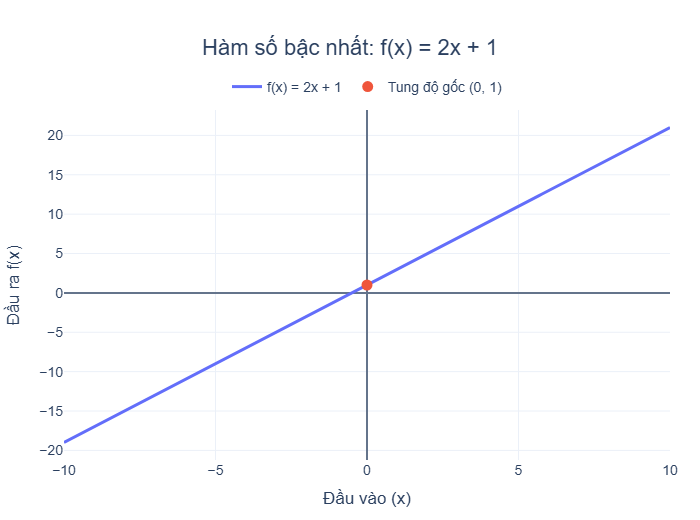

In [9]:
linear_caption = r"""
<strong>Hàm số bậc nhất</strong> có dạng \(f(x)=mx+b\).
Ở đây, \(f(x)=2x+1\) và đồ thị của nó là một <strong>đường thẳng</strong>.

<br><br>

<strong>Hệ số góc (slope)</strong> là \(m=2\).

Điều này có nghĩa là mỗi khi \(x\) tăng thêm 1 đơn vị,
giá trị \(f(x)\) tăng thêm 2 đơn vị.

<br><br>

<strong>Tung độ gốc (y-intercept)</strong> là \(b=1\).

Do đó, đường thẳng cắt trục y tại điểm:

\[
(0,1)
\]

<br>

<strong>Vì sao đồ thị là một đường thẳng?</strong>

Vì tốc độ thay đổi luôn không đổi:

\[
\frac{f(x+1)-f(x)}{1}=2
\]

với mọi giá trị của \(x\). Tốc độ thay đổi không đổi luôn tạo ra một đường thẳng.
"""


add_caption(
    fig=fig_linear,

    caption=linear_caption,

    title="Tìm hiểu hàm số bậc nhất",

    html_name="linear_function.html"
)

# Xuất HTML hàm số bậc nhất

In [10]:
export_figure(
    fig=fig_linear,

    filename="linear_function.html",

    caption=linear_caption,

    caption_title="Tìm hiểu hàm số bậc nhất",

    page_title="Hàm số bậc nhất - AI From Scratch"
)

Exported successfully: D:\lh222k\ai-from-scratch\visualizations\linear_function.html
File size: 4723.32 KB


WindowsPath('D:/lh222k/ai-from-scratch/visualizations/linear_function.html')

# Định nghĩa hàm số bậc hai

In [11]:
def quadratic_function(x):
    """
    Quadratic function: g(x) = x²
    """
    return x ** 2


# Generate input values
x_quadratic = np.linspace(-5, 5, 300)

# Calculate output values
y_quadratic = quadratic_function(x_quadratic)


# Explicit data points (computed from the function, not hard-coded)
x_points = np.array([-2, -1, 0, 1, 2])

y_points = quadratic_function(x_points)

assert list(y_points) == [4, 1, 0, 1, 4]


print("Hàm số bậc hai: g(x) = x²")

print("\nData points:")

for x, y in zip(x_points, y_points):

    print(f"({x}, {y})")

Hàm số bậc hai: g(x) = x²

Data points:
(-2, 4)
(-1, 1)
(0, 0)
(1, 1)
(2, 4)


# Tạo biểu đồ hàm số bậc hai

In [12]:
fig_quadratic = go.Figure()


# Add quadratic function
fig_quadratic.add_trace(
    go.Scatter(

        x=x_quadratic,
        y=y_quadratic,

        mode="lines",

        name="g(x) = x²",

        line=dict(
            width=3
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "g(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Add explicit data points
fig_quadratic.add_trace(
    go.Scatter(

        x=x_points,
        y=y_points,

        mode="markers",

        name="Các điểm nổi bật",

        marker=dict(
            size=11,
            symbol="circle",
            line=dict(
                width=1
            )
        ),

        hovertemplate=(
            "Điểm: (%{x}, %{y})"
            "<extra></extra>"
        )

    )
)


# Configure figure (displayed together with its caption in the next cell)
fig_quadratic = configure_figure(
    fig=fig_quadratic,

    title="Hàm số bậc hai: g(x) = x²",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra g(x)"
)

# Thêm chú thích cho hàm số bậc hai

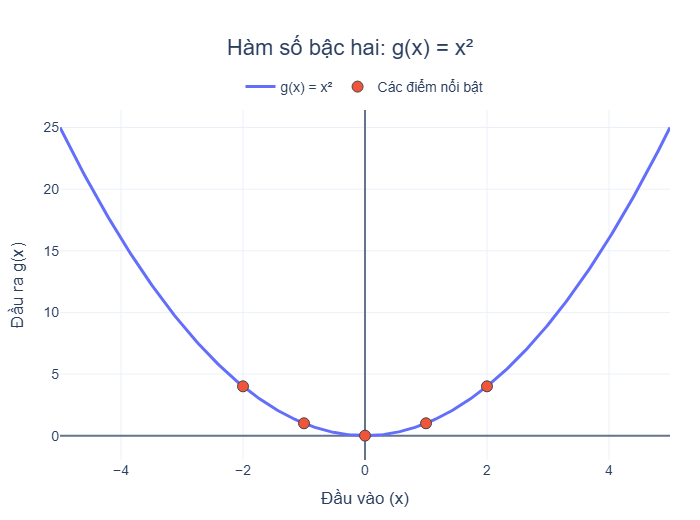

In [13]:
quadratic_caption = r"""
<strong>Hàm số bậc hai</strong> có dạng
\(g(x)=ax^2+bx+c\) với \(a\neq 0\).
Ở đây, \(g(x)=x^2\) và đồ thị của nó là một <strong>parabol</strong> mở lên trên.

<br><br>

<strong>Đỉnh (vertex)</strong> của parabol nằm tại:

\[
(0,0)
\]

Đây là điểm thấp nhất (cực tiểu) của hàm số.

<br><br>

Đồ thị <strong>đối xứng qua trục y</strong>,
vì \(g(-x)=(-x)^2=x^2=g(x)\).

Ví dụ:

\[
g(-2)=(-2)^2=4
\]

\[
g(2)=2^2=4
\]

Do đó:

\[
g(-2)=g(2)
\]

Phép bình phương làm mất dấu của đầu vào, nên hai số đối nhau
cho cùng một kết quả.

<br><br>

<strong>Các điểm được làm nổi bật:</strong>

\[
(-2,4),\;(-1,1),\;(0,0),\;(1,1),\;(2,4)
\]

<br>

<strong>Hàm bậc nhất và hàm bậc hai khác nhau thế nào?</strong>

Hàm bậc nhất như \(f(x)=2x+1\) có tốc độ thay đổi không đổi,
nên đồ thị là đường thẳng. Hàm bậc hai có tốc độ thay đổi thay đổi
(độ dốc của \(x^2\) là \(2x\)), nên đồ thị cong thành parabol.
"""


add_caption(
    fig=fig_quadratic,

    caption=quadratic_caption,

    title="Tìm hiểu hàm số bậc hai",

    html_name="quadratic_function.html"
)

# Xuất HTML hàm số bậc hai

In [14]:
export_figure(
    fig=fig_quadratic,

    filename="quadratic_function.html",

    caption=quadratic_caption,

    caption_title="Tìm hiểu hàm số bậc hai",

    page_title="Hàm số bậc hai - AI From Scratch"
)

Exported successfully: D:\lh222k\ai-from-scratch\visualizations\quadratic_function.html
File size: 4726.36 KB


WindowsPath('D:/lh222k/ai-from-scratch/visualizations/quadratic_function.html')

# Định nghĩa hàm số có điểm bị loại bỏ (giới hạn)

$g(x)=\dfrac{x^2-1}{x-1}$ không xác định tại $x=1$, nhưng với $x\neq 1$ thì $g(x)=x+1$. Đồ thị là đường thẳng $y=x+1$ **bị khuyết một điểm** tại $(1,2)$, và giới hạn khi $x\to 1$ bằng $2$.

In [15]:
def removable_discontinuity_function(x):
    """
    g(x) = (x^2 - 1) / (x - 1)

    Với x != 1 : g(x) = x + 1.
    Tại x = 1  : g(1) = 0/0, không xác định -> trả về NaN.
    """
    x = np.asarray(x, dtype=float)
    y = np.full_like(x, np.nan)

    defined = ~np.isclose(x, 1.0)
    y[defined] = (x[defined] ** 2 - 1) / (x[defined] - 1)

    return y


# Dữ liệu cho đường thẳng (NaN tại x = 1 tạo ra khoảng hở)
x_limit = np.linspace(-4, 4, 401)
y_limit = removable_discontinuity_function(x_limit)

# Điểm bị loại bỏ và giá trị giới hạn
HOLE_X = 1
LIMIT_VALUE = 2

# Các giá trị x tiến gần 1 từ bên trái và bên phải
x_left = np.array([0.0, 0.5, 0.9, 0.99])
x_right = np.array([2.0, 1.5, 1.1, 1.01])

x_approach = np.concatenate([x_left, x_right])
y_approach = removable_discontinuity_function(x_approach)

# Kiểm tra toán học
assert np.isnan(removable_discontinuity_function([HOLE_X])[0])
assert np.allclose(y_approach, x_approach + 1)
assert HOLE_X + 1 == LIMIT_VALUE


print("g(x) = (x^2 - 1) / (x - 1)")
print("g(1) = không xác định (0/0)")
print("Giới hạn khi x -> 1:", LIMIT_VALUE)

print("\n" + f"{'x':>8} | {'g(x)':>8}")
print("-" * 19)

for x_value, y_value in zip(x_approach, y_approach):

    print(f"{x_value:>8.3f} | {y_value:>8.3f}")

g(x) = (x^2 - 1) / (x - 1)
g(1) = không xác định (0/0)
Giới hạn khi x -> 1: 2

       x |     g(x)
-------------------
   0.000 |    1.000
   0.500 |    1.500
   0.900 |    1.900
   0.990 |    1.990
   2.000 |    3.000
   1.500 |    2.500
   1.100 |    2.100
   1.010 |    2.010


# Tạo biểu đồ giới hạn với vòng tròn rỗng

In [16]:
LINE_COLOR = "#2563eb"
APPROACH_COLOR = "#f97316"

fig_limit = go.Figure()


# Đường thẳng y = x + 1 (bị khuyết tại x = 1)
fig_limit.add_trace(
    go.Scatter(

        x=x_limit,
        y=y_limit,

        mode="lines",

        name="g(x) = (x² − 1)/(x − 1)",

        line=dict(
            width=3,
            color=LINE_COLOR
        ),

        connectgaps=False,

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "g(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Các điểm x tiến gần 1 từ hai phía
fig_limit.add_trace(
    go.Scatter(

        x=x_approach,
        y=y_approach,

        mode="markers",

        name="x tiến gần 1",

        marker=dict(
            size=9,
            color=APPROACH_COLOR
        ),

        hovertemplate=(
            "x = %{x}<br>"
            "g(x) = %{y:.3f}"
            "<extra></extra>"
        )

    )
)


# Vòng tròn rỗng tại (1, 2): điểm bị loại bỏ
fig_limit.add_trace(
    go.Scatter(

        x=[HOLE_X],
        y=[LIMIT_VALUE],

        mode="markers",

        name="Điểm bị loại bỏ (1, 2)",

        marker=dict(
            symbol="circle",
            size=15,
            color="white",
            line=dict(
                width=3,
                color=LINE_COLOR
            )
        ),

        hovertemplate=(
            "Điểm bị loại bỏ<br>"
            "g(1) không xác định<br>"
            "Giới hạn = 2"
            "<extra></extra>"
        )

    )
)


# Đường gióng: giới hạn y = 2 khi x -> 1
fig_limit.add_shape(
    type="line",
    x0=-4, x1=HOLE_X,
    y0=LIMIT_VALUE, y1=LIMIT_VALUE,
    line=dict(color="#94a3b8", width=2, dash="dot")
)

fig_limit.add_shape(
    type="line",
    x0=HOLE_X, x1=HOLE_X,
    y0=-3.5, y1=LIMIT_VALUE,
    line=dict(color="#94a3b8", width=2, dash="dot")
)


# Chú thích điểm bị loại bỏ
fig_limit.add_annotation(
    x=HOLE_X,
    y=LIMIT_VALUE,
    text="Lỗ hổng tại (1, 2)<br>g(1) không xác định<br>Giới hạn = 2",
    showarrow=True,
    arrowhead=2,
    ax=-110,
    ay=-70,
    align="left",
    bgcolor="white",
    bordercolor="#cbd5e1",
    borderwidth=1
)


fig_limit = configure_figure(
    fig=fig_limit,

    title="g(x) = (x² − 1) / (x − 1)",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra g(x)"
)

fig_limit = (
    fig_limit
    .update_xaxes(range=[-4, 4], dtick=1)
    .update_yaxes(range=[-3.5, 5.5], tick0=0, dtick=1)
)

# Thêm chú thích cho biểu đồ giới hạn

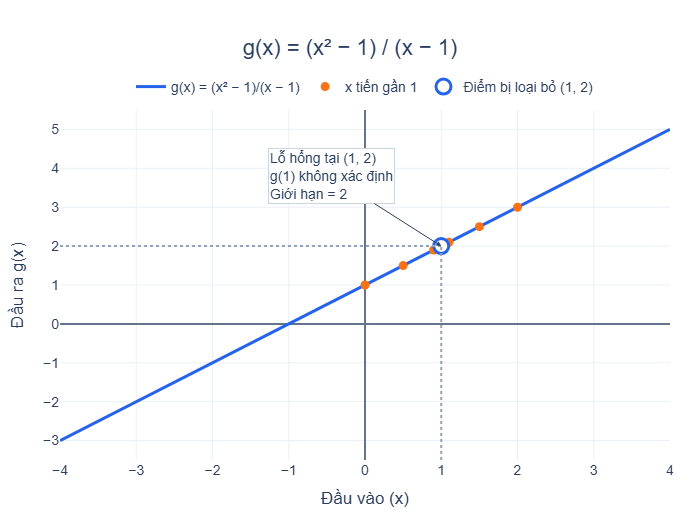

In [17]:
limit_caption = r"""
Xét hàm số \(g(x)=\dfrac{x^2-1}{x-1}\). Hàm số này
<strong>không xác định tại \(x=1\)</strong> vì mẫu số bằng 0
(\(g(1)=\dfrac{0}{0}\)).

<br><br>

Với mọi \(x\neq 1\), ta có thể rút gọn:

\[
g(x)=\frac{(x-1)(x+1)}{x-1}=x+1
\]

Vì vậy, đồ thị của \(g(x)\) là
<strong>đường thẳng \(y=x+1\) bị loại bỏ một điểm duy nhất</strong>
tại \((1,2)\), được biểu thị bằng một
<strong>vòng tròn rỗng</strong>.

<br><br>

<strong>Giới hạn (limit)</strong> khi \(x\) tiến đến 1 là giá trị
\(y\) mà hàm số tiến gần đến, tức là 2:

\[
\lim_{x\to 1}\frac{x^2-1}{x-1}=2
\]

Các điểm màu cam cho thấy: khi \(x\) tiến gần 1 từ bên trái
(0,9; 0,99) hoặc từ bên phải (1,1; 1,01), giá trị \(g(x)\)
đều tiến gần 2.

<br>

<strong>Ý tưởng chính:</strong>

Giới hạn chỉ quan tâm hàm số <em>tiến gần</em> đến giá trị nào,
không yêu cầu hàm số phải xác định tại điểm đó.
Ở đây \(g(1)\) không tồn tại, nhưng giới hạn vẫn bằng 2.
"""


add_caption(
    fig=fig_limit,

    caption=limit_caption,

    title="Tìm hiểu giới hạn và điểm bị loại bỏ",

    html_name="limit_function.html"
)

# Xuất HTML biểu đồ giới hạn

In [18]:
export_figure(
    fig=fig_limit,

    filename="limit_function.html",

    caption=limit_caption,

    caption_title="Tìm hiểu giới hạn và điểm bị loại bỏ",

    page_title="Giới hạn của hàm số - AI From Scratch"
)

Exported successfully: D:\lh222k\ai-from-scratch\visualizations\limit_function.html
File size: 4730.03 KB


WindowsPath('D:/lh222k/ai-from-scratch/visualizations/limit_function.html')

# Định nghĩa hàm số cho ví dụ giới hạn x → 3

Xét $f(x)=2x+1$. Khi $x$ tiến gần $3$ từ **bên trái** (2,9; 2,99; ...) và từ **bên phải** (3,1; 3,01; ...), $f(x)$ tiến gần $7$. Giới hạn mô tả giá trị đích này: $\lim_{x\to 3}(2x+1)=7$.

In [19]:
def approach_function(x):
    """
    Hàm số: f(x) = 2x + 1
    """
    return 2 * np.asarray(x, dtype=float) + 1


# Điểm mà x tiến đến và giá trị đích (giới hạn)
APPROACH_X = 3
TARGET_VALUE = 7

# Đường thẳng (vùng phóng to quanh x = 3)
x_line_3 = np.linspace(2.5, 3.5, 200)
y_line_3 = approach_function(x_line_3)

# Các giá trị x tiến gần 3 từ bên trái và bên phải
x_from_left = np.array([2.9, 2.99, 2.999])
x_from_right = np.array([3.1, 3.01, 3.001])

y_from_left = approach_function(x_from_left)
y_from_right = approach_function(x_from_right)

# Kiểm tra toán học
assert np.isclose(approach_function(APPROACH_X), TARGET_VALUE)

# Càng gần 3 thì f(x) càng gần 7
assert np.all(np.diff(np.abs(y_from_left - TARGET_VALUE)) < 0)
assert np.all(np.diff(np.abs(y_from_right - TARGET_VALUE)) < 0)


print("f(x) = 2x + 1")
print(f"Giới hạn khi x -> {APPROACH_X}: {TARGET_VALUE}")

print("\n" + f"{'Phía':<8} | {'x':>7} | {'f(x)':>7} | {'|f(x) - 7|':>10}")
print("-" * 41)

for side, xs, ys in [
    ("Trái", x_from_left, y_from_left),
    ("Phải", x_from_right, y_from_right),
]:

    for x_value, y_value in zip(xs, ys):

        print(
            f"{side:<8} | {x_value:>7.3f} | {y_value:>7.3f} | "
            f"{abs(y_value - TARGET_VALUE):>10.3f}"
        )

f(x) = 2x + 1
Giới hạn khi x -> 3: 7

Phía     |       x |    f(x) | |f(x) - 7|
-----------------------------------------
Trái     |   2.900 |   6.800 |      0.200
Trái     |   2.990 |   6.980 |      0.020
Trái     |   2.999 |   6.998 |      0.002
Phải     |   3.100 |   7.200 |      0.200
Phải     |   3.010 |   7.020 |      0.020
Phải     |   3.001 |   7.002 |      0.002


# Tạo biểu đồ x tiến gần 3 từ hai phía

In [20]:
LEFT_COLOR = "#f97316"
RIGHT_COLOR = "#16a34a"
TARGET_COLOR = "#dc2626"

fig_approach = go.Figure()


# Đường thẳng f(x) = 2x + 1
fig_approach.add_trace(
    go.Scatter(

        x=x_line_3,
        y=y_line_3,

        mode="lines",

        name="f(x) = 2x + 1",

        line=dict(
            width=3,
            color="#2563eb"
        ),

        hovertemplate=(
            "x = %{x:.3f}<br>"
            "f(x) = %{y:.3f}"
            "<extra></extra>"
        )

    )
)


# Các điểm tiến gần từ bên trái
fig_approach.add_trace(
    go.Scatter(

        x=x_from_left,
        y=y_from_left,

        mode="markers",

        name="x tiến gần 3 từ bên trái",

        marker=dict(
            size=10,
            color=LEFT_COLOR
        ),

        hovertemplate=(
            "Bên trái<br>"
            "x = %{x}<br>"
            "f(x) = %{y:.3f}"
            "<extra></extra>"
        )

    )
)


# Các điểm tiến gần từ bên phải
fig_approach.add_trace(
    go.Scatter(

        x=x_from_right,
        y=y_from_right,

        mode="markers",

        name="x tiến gần 3 từ bên phải",

        marker=dict(
            size=10,
            color=RIGHT_COLOR
        ),

        hovertemplate=(
            "Bên phải<br>"
            "x = %{x}<br>"
            "f(x) = %{y:.3f}"
            "<extra></extra>"
        )

    )
)


# Giá trị đích (giới hạn)
fig_approach.add_trace(
    go.Scatter(

        x=[APPROACH_X],
        y=[TARGET_VALUE],

        mode="markers",

        name="Giá trị đích: 7",

        marker=dict(
            symbol="diamond",
            size=13,
            color=TARGET_COLOR,
            line=dict(
                width=1,
                color="white"
            )
        ),

        hovertemplate=(
            "Giới hạn khi x → 3<br>"
            "L = 7"
            "<extra></extra>"
        )

    )
)


# Đường gióng: x = 3 và y = 7
fig_approach.add_shape(
    type="line",
    x0=APPROACH_X, x1=APPROACH_X,
    y0=6, y1=TARGET_VALUE,
    line=dict(color="#94a3b8", width=2, dash="dot")
)

fig_approach.add_shape(
    type="line",
    x0=2.5, x1=APPROACH_X,
    y0=TARGET_VALUE, y1=TARGET_VALUE,
    line=dict(color="#94a3b8", width=2, dash="dot")
)


# Chú thích hướng tiến gần
fig_approach.add_annotation(
    x=2.9, y=6.8,
    text="x → 3 từ bên trái",
    showarrow=True, arrowhead=2,
    ax=-60, ay=45,
    font=dict(color=LEFT_COLOR)
)

fig_approach.add_annotation(
    x=3.1, y=7.2,
    text="x → 3 từ bên phải",
    showarrow=True, arrowhead=2,
    ax=70, ay=45,
    font=dict(color=RIGHT_COLOR)
)

fig_approach.add_annotation(
    x=APPROACH_X, y=TARGET_VALUE,
    text="Giới hạn: f(x) → 7",
    showarrow=True, arrowhead=2,
    ax=-95, ay=-60,
    font=dict(color=TARGET_COLOR),
    bgcolor="white",
    bordercolor="#cbd5e1",
    borderwidth=1
)


fig_approach = configure_figure(
    fig=fig_approach,

    title="f(x) = 2x + 1 khi x tiến đến 3",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra f(x)"
)

fig_approach = (
    fig_approach
    .update_xaxes(range=[2.5, 3.5], dtick=0.1)
    .update_yaxes(range=[6, 8], dtick=0.5)
)

# Thêm chú thích cho biểu đồ x tiến gần 3

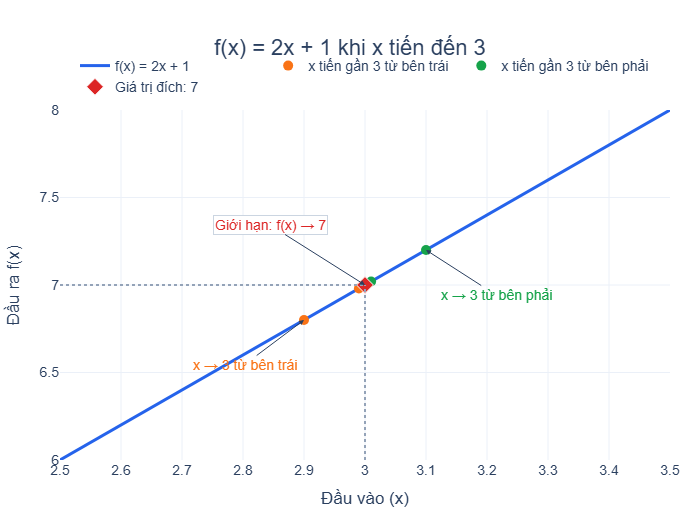

In [21]:
approach_caption = r"""
Xét hàm số \(f(x)=2x+1\) khi \(x\) tiến gần đến 3.

<br><br>

Khi các giá trị đầu vào \(x\) tiến gần 3 từ <strong>bên trái</strong>
(chẳng hạn 2,9; 2,99) và từ <strong>bên phải</strong>
(chẳng hạn 3,1; 3,01), các giá trị đầu ra \(f(x)\) tiến gần 7:

\[
f(2{,}9)=6{,}8,\quad f(2{,}99)=6{,}98,\quad f(2{,}999)=6{,}998
\]

\[
f(3{,}1)=7{,}2,\quad f(3{,}01)=7{,}02,\quad f(3{,}001)=7{,}002
\]

<br>

<strong>Giới hạn (limit)</strong> mô tả giá trị đích này, tức là 7:

\[
\lim_{x\to 3^-}f(x)=7,\qquad
\lim_{x\to 3^+}f(x)=7
\quad\Rightarrow\quad
\lim_{x\to 3}(2x+1)=7
\]

<br>

<strong>Ý tưởng chính:</strong>

Giới hạn tồn tại khi giá trị của \(f(x)\) tiến gần cùng một số
từ cả hai phía. Càng chọn \(x\) gần 3, khoảng cách
\(|f(x)-7|\) càng nhỏ.
"""


add_caption(
    fig=fig_approach,

    caption=approach_caption,

    title="Tìm hiểu giới hạn khi x tiến đến 3",

    html_name="limit_approach_function.html"
)

# Xuất HTML biểu đồ x tiến gần 3

In [22]:
export_figure(
    fig=fig_approach,

    filename="limit_approach_function.html",

    caption=approach_caption,

    caption_title="Tìm hiểu giới hạn khi x tiến đến 3",

    page_title="Giới hạn khi x tiến đến 3 - AI From Scratch"
)

Exported successfully: D:\lh222k\ai-from-scratch\visualizations\limit_approach_function.html
File size: 4724.83 KB


WindowsPath('D:/lh222k/ai-from-scratch/visualizations/limit_approach_function.html')

# Định nghĩa đường cát tuyến và tốc độ thay đổi trung bình

Trên đồ thị $f(x)=x^2$, đường nối hai điểm $(1,1)$ và $(3,9)$ gọi là **đường cát tuyến (secant line)**. Hệ số góc của nó là **tốc độ thay đổi trung bình** giữa $x=1$ và $x=3$:

$$\dfrac{f(3)-f(1)}{3-1}=\dfrac{9-1}{2}=4$$

In [23]:
def average_rate_of_change(func, x_start, x_end):
    """
    Tốc độ thay đổi trung bình của func trên [x_start, x_end]
    = hệ số góc của đường cát tuyến nối hai điểm.
    """
    return (func(x_end) - func(x_start)) / (x_end - x_start)


# Hai điểm tạo nên đường cát tuyến
x_secant = np.array([1.0, 3.0])
y_secant = quadratic_function(x_secant)

# Tốc độ thay đổi trung bình giữa x = 1 và x = 3
secant_slope = average_rate_of_change(quadratic_function, 1, 3)

# Đồ thị f(x) = x^2 trong vùng quan sát
x_curve_secant = np.linspace(-0.5, 3.5, 300)
y_curve_secant = quadratic_function(x_curve_secant)

# Kiểm tra toán học
assert list(y_secant) == [1.0, 9.0]
assert secant_slope == 4

# Hàm bậc hai: tốc độ thay đổi trung bình phụ thuộc vào khoảng chọn
assert average_rate_of_change(quadratic_function, 0, 1) == 1


print("f(x) = x²")
print(f"Điểm 1: ({x_secant[0]:.0f}, {y_secant[0]:.0f})")
print(f"Điểm 2: ({x_secant[1]:.0f}, {y_secant[1]:.0f})")

print(f"\nΔx = {x_secant[1] - x_secant[0]:.0f}")
print(f"Δy = {y_secant[1] - y_secant[0]:.0f}")
print(f"Tốc độ thay đổi trung bình = Δy/Δx = {secant_slope:.0f}")

f(x) = x²
Điểm 1: (1, 1)
Điểm 2: (3, 9)

Δx = 2
Δy = 8
Tốc độ thay đổi trung bình = Δy/Δx = 4


# Tạo biểu đồ đường cát tuyến

In [24]:
SECANT_COLOR = "#ef4444"

fig_secant = go.Figure()


# Đồ thị f(x) = x²
fig_secant.add_trace(
    go.Scatter(

        x=x_curve_secant,
        y=y_curve_secant,

        mode="lines",

        name="f(x) = x²",

        line=dict(
            width=3,
            color="#2563eb"
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "f(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Đường cát tuyến nối (1, 1) và (3, 9)
fig_secant.add_trace(
    go.Scatter(

        x=x_secant,
        y=y_secant,

        mode="lines+markers",

        name="Đường cát tuyến (tốc độ thay đổi trung bình)",

        line=dict(
            width=3,
            color=SECANT_COLOR
        ),

        marker=dict(
            size=11,
            color=SECANT_COLOR
        ),

        hovertemplate=(
            "Điểm (%{x:.0f}, %{y:.0f})"
            "<extra></extra>"
        )

    )
)


# Tam giác thể hiện Δx và Δy (đường nét đứt)
fig_secant.add_shape(
    type="line",
    x0=1, x1=3, y0=1, y1=1,
    line=dict(color="#94a3b8", width=2, dash="dot")
)

fig_secant.add_shape(
    type="line",
    x0=3, x1=3, y0=1, y1=9,
    line=dict(color="#94a3b8", width=2, dash="dot")
)

fig_secant.add_annotation(
    x=2, y=1,
    text="Δx = 2",
    showarrow=False,
    yshift=-16,
    font=dict(color="#475569")
)

fig_secant.add_annotation(
    x=3, y=5,
    text="Δy = 8",
    showarrow=False,
    xshift=34,
    font=dict(color="#475569")
)

fig_secant.add_annotation(
    x=1.1, y=8.2,
    text="Hệ số góc = Δy / Δx = 8 / 2 = 4",
    showarrow=False,
    xanchor="left",
    font=dict(color=SECANT_COLOR),
    bgcolor="white",
    bordercolor="#fecaca",
    borderwidth=1
)


fig_secant = configure_figure(
    fig=fig_secant,

    title="Đường cát tuyến của f(x) = x²",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra f(x)"
)

fig_secant = (
    fig_secant
    .update_xaxes(range=[-0.5, 3.8], dtick=1)
    .update_yaxes(range=[-0.5, 11], dtick=2)
)

# Thêm chú thích cho biểu đồ đường cát tuyến

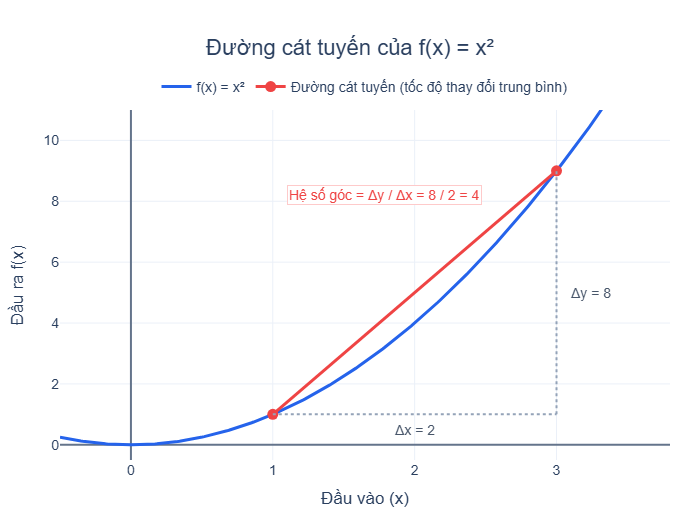

In [25]:
secant_caption = r"""
Đường màu đỏ nối hai điểm \((1,1)\) và \((3,9)\) trên đồ thị của
\(f(x)=x^2\). Đường thẳng đi qua hai điểm của một đồ thị được gọi là
<strong>đường cát tuyến (secant line)</strong>.

<br><br>

<strong>Hệ số góc</strong> của nó biểu diễn
<strong>tốc độ thay đổi trung bình</strong> giữa \(x=1\) và \(x=3\):

\[
\frac{f(3)-f(1)}{3-1}=\frac{9-1}{2}=4
\]

Nghĩa là: trung bình, trong khoảng từ \(x=1\) đến \(x=3\), mỗi khi
\(x\) tăng 1 đơn vị thì \(f(x)\) tăng 4 đơn vị.

<br>

<strong>Ý tưởng chính:</strong>

Với hàm bậc hai, tốc độ thay đổi trung bình <em>phụ thuộc vào khoảng
được chọn</em>. Chẳng hạn, giữa \(x=0\) và \(x=1\) nó chỉ bằng 1,
còn giữa \(x=1\) và \(x=3\) nó bằng 4. Đường cát tuyến chỉ cho biết
mức thay đổi <em>trung bình</em>, không phải tốc độ thay đổi tại một điểm.
"""


add_caption(
    fig=fig_secant,

    caption=secant_caption,

    title="Tìm hiểu đường cát tuyến và tốc độ thay đổi trung bình",

    html_name="secant_line_function.html"
)

# Xuất HTML biểu đồ đường cát tuyến

In [26]:
export_figure(
    fig=fig_secant,

    filename="secant_line_function.html",

    caption=secant_caption,

    caption_title="Tìm hiểu đường cát tuyến và tốc độ thay đổi trung bình",

    page_title="Đường cát tuyến - AI From Scratch"
)

Exported successfully: D:\lh222k\ai-from-scratch\visualizations\secant_line_function.html
File size: 4727.34 KB


WindowsPath('D:/lh222k/ai-from-scratch/visualizations/secant_line_function.html')

# Định nghĩa cát tuyến tiến dần đến tiếp tuyến (animation)

Cố định điểm $P=(1,1)$ trên đồ thị $f(x)=x^2$ và cho điểm thứ hai $Q$ tiến dần về $P$. Hệ số góc của cát tuyến $PQ$ với $Q=(1+h,\,(1+h)^2)$ là

$$\dfrac{f(1+h)-f(1)}{h}=\dfrac{(1+h)^2-1}{h}=2+h$$

Khi $h\to 0$, hệ số góc này tiến gần $2$: đó là hệ số góc của **tiếp tuyến** tại $x=1$ (tốc độ thay đổi tức thời).

In [27]:
# Điểm cố định P trên đồ thị f(x) = x²
X_FIXED = 1.0
Y_FIXED = float(quadratic_function(X_FIXED))

# Điểm thứ hai Q tiến dần về P (h = 2, 1, 0.5, 0.1)
x_moving = [3.0, 2.0, 1.5, 1.1]
y_moving = [float(quadratic_function(x)) for x in x_moving]

# Hệ số góc của các đường cát tuyến PQ
secant_slopes = [
    average_rate_of_change(quadratic_function, X_FIXED, x)
    for x in x_moving
]

# Hệ số góc của tiếp tuyến tại x = 1: f'(x) = 2x
tangent_slope = 2 * X_FIXED
x_tangent = np.array([0.4, 1.6])
y_tangent = Y_FIXED + tangent_slope * (x_tangent - X_FIXED)

# Màu của các điểm Q (cam, vàng, xanh lá, xanh lơ)
Q_COLORS = ["#f97316", "#eab308", "#22c55e", "#06b6d4"]

# Kiểm tra toán học: hệ số góc cát tuyến = 2 + h
for x, slope in zip(x_moving, secant_slopes):
    assert np.isclose(slope, 2 + (x - X_FIXED))

assert np.allclose(secant_slopes, [4, 3, 2.5, 2.1])

# Khoảng cách tới hệ số góc tiếp tuyến giảm dần
gaps = np.abs(np.array(secant_slopes) - tangent_slope)
assert np.all(np.diff(gaps) < 0)


print("P = (1, 1)")
print(f"Hệ số góc tiếp tuyến tại x = 1: {tangent_slope:.0f}")

print("\n" + f"{'x của Q':>8} | {'h':>5} | {'Hệ số góc PQ':>12} | {'2 + h':>6}")
print("-" * 42)

for x, slope in zip(x_moving, secant_slopes):

    h = x - X_FIXED

    print(f"{x:>8.2f} | {h:>5.2f} | {slope:>12.2f} | {2 + h:>6.2f}")

P = (1, 1)
Hệ số góc tiếp tuyến tại x = 1: 2

 x của Q |     h | Hệ số góc PQ |  2 + h
------------------------------------------
    3.00 |  2.00 |         4.00 |   4.00
    2.00 |  1.00 |         3.00 |   3.00
    1.50 |  0.50 |         2.50 |   2.50
    1.10 |  0.10 |         2.10 |   2.10


# Lời giải thích cho từng bước animation

In [28]:
def vn(number):
    """Định dạng số theo kiểu Việt Nam (dấu phẩy thập phân)."""
    return f"{number:g}".replace(".", ",")


N_STEPS = len(x_moving) + 1   # bước 0..4 chọn Q, bước 5 = tiếp tuyến
LAST_STEP = N_STEPS


def explanation_lines(step):
    """Các dòng giải thích hiển thị trong biểu đồ ở mỗi bước."""

    if step == 0:
        return [
            "<b>Bước 0/5 · Điểm cố định</b>",
            "P = (1; 1) nằm trên đồ thị f(x) = x².",
            "Mục tiêu: tìm độ dốc của đồ thị tại P.",
            "Bấm Play để xem từng bước."
        ]

    if step <= len(x_moving):

        i = step - 1
        xq, yq, slope = x_moving[i], y_moving[i], secant_slopes[i]

        history = " → ".join(vn(s) for s in secant_slopes[:step])

        return [
            f"<b>Bước {step}/5 · Chọn điểm Q thứ hai</b>",
            f"Q = ({vn(xq)}; {vn(yq)}) nằm trên đồ thị.",
            f"Hệ số góc PQ = ({vn(yq)} − 1) / ({vn(xq)} − 1) = {vn(slope)}",
            f"Các hệ số góc cát tuyến: {history}"
        ]

    history = " → ".join(vn(s) for s in secant_slopes) + " → " + vn(tangent_slope)

    return [
        "<b>Bước 5/5 · Q tiến sát P (bấm Play để xem lại)</b>",
        f"Hệ số góc cát tuyến: {history}",
        f"Đường tím: tiếp tuyến tại x = 1 (hệ số góc {vn(tangent_slope)})",
        "= tốc độ thay đổi tức thời tại x = 1."
    ]


def step_annotations(step):
    """Annotation giải thích + nhãn điểm P cho một bước."""

    return [
        dict(
            xref="paper", yref="paper",
            x=0, y=1.02,
            xanchor="left", yanchor="bottom",
            align="left",
            showarrow=False,
            text="<br>".join(explanation_lines(step)),
            font=dict(size=13, color="#1e293b"),
            bgcolor="#f8fafc",
            bordercolor="#cbd5e1",
            borderwidth=1,
            borderpad=8
        ),
        dict(
            x=X_FIXED, y=Y_FIXED,
            text="P(1; 1)",
            showarrow=False,
            xanchor="left",
            xshift=10, yshift=-16,
            font=dict(size=13, color="#dc2626")
        )
    ]


for step in range(LAST_STEP + 1):

    print(f"--- Bước {step} ---")

    for line in explanation_lines(step):

        print(line.replace("<b>", "").replace("</b>", ""))

--- Bước 0 ---
Bước 0/5 · Điểm cố định
P = (1; 1) nằm trên đồ thị f(x) = x².
Mục tiêu: tìm độ dốc của đồ thị tại P.
Bấm Play để xem từng bước.
--- Bước 1 ---
Bước 1/5 · Chọn điểm Q thứ hai
Q = (3; 9) nằm trên đồ thị.
Hệ số góc PQ = (9 − 1) / (3 − 1) = 4
Các hệ số góc cát tuyến: 4
--- Bước 2 ---
Bước 2/5 · Chọn điểm Q thứ hai
Q = (2; 4) nằm trên đồ thị.
Hệ số góc PQ = (4 − 1) / (2 − 1) = 3
Các hệ số góc cát tuyến: 4 → 3
--- Bước 3 ---
Bước 3/5 · Chọn điểm Q thứ hai
Q = (1,5; 2,25) nằm trên đồ thị.
Hệ số góc PQ = (2,25 − 1) / (1,5 − 1) = 2,5
Các hệ số góc cát tuyến: 4 → 3 → 2,5
--- Bước 4 ---
Bước 4/5 · Chọn điểm Q thứ hai
Q = (1,1; 1,21) nằm trên đồ thị.
Hệ số góc PQ = (1,21 − 1) / (1,1 − 1) = 2,1
Các hệ số góc cát tuyến: 4 → 3 → 2,5 → 2,1
--- Bước 5 ---
Bước 5/5 · Q tiến sát P (bấm Play để xem lại)
Hệ số góc cát tuyến: 4 → 3 → 2,5 → 2,1 → 2
Đường tím: tiếp tuyến tại x = 1 (hệ số góc 2)
= tốc độ thay đổi tức thời tại x = 1.


# Tạo biểu đồ animation (Play / Pause / thanh trượt)

In [29]:
PURPLE = "#a855f7"
POINT_COLOR = "#ef4444"

x_curve_anim = np.linspace(-0.5, 3.5, 300)
y_curve_anim = quadratic_function(x_curve_anim)


def dynamic_traces(step):
    """
    Dữ liệu của các trace thay đổi theo bước:
    4 đường cát tuyến, các điểm Q và đường tiếp tuyến.
    """

    traces = []

    for i in range(len(x_moving)):

        if step >= i + 1:
            traces.append(go.Scatter(
                x=[X_FIXED, x_moving[i]],
                y=[Y_FIXED, y_moving[i]]
            ))
        else:
            traces.append(go.Scatter(x=[], y=[]))

    n_visible = min(step, len(x_moving))

    traces.append(go.Scatter(
        x=x_moving[:n_visible],
        y=y_moving[:n_visible],
        marker=dict(color=Q_COLORS[:n_visible])
    ))

    if step >= LAST_STEP:
        traces.append(go.Scatter(x=x_tangent, y=y_tangent))
    else:
        traces.append(go.Scatter(x=[], y=[]))

    return traces


fig_tangent = go.Figure()

# Trace 0: đồ thị f(x) = x²
fig_tangent.add_trace(go.Scatter(
    x=x_curve_anim, y=y_curve_anim,
    mode="lines", name="f(x) = x²",
    line=dict(width=3, color="#2563eb"),
    hovertemplate="x = %{x:.2f}<br>f(x) = %{y:.2f}<extra></extra>"
))

# Trace 1: điểm cố định P
fig_tangent.add_trace(go.Scatter(
    x=[X_FIXED], y=[Y_FIXED],
    mode="markers", name="Điểm cố định P (1, 1)",
    marker=dict(size=13, color=POINT_COLOR),
    hovertemplate="P = (1, 1)<extra></extra>"
))

# Trace 2..5: các đường cát tuyến PQ (nét đứt)
for i in range(len(x_moving)):

    fig_tangent.add_trace(go.Scatter(
        x=[X_FIXED, x_moving[i]],
        y=[Y_FIXED, y_moving[i]],
        mode="lines",
        name="Các đường cát tuyến PQ",
        showlegend=(i == 0),
        legendgroup="secants",
        line=dict(width=3, color=Q_COLORS[i], dash="dot"),
        hovertemplate=(
            f"Cát tuyến PQ<br>Hệ số góc = {vn(secant_slopes[i])}"
            "<extra></extra>"
        )
    ))

# Trace 6: các điểm Q
fig_tangent.add_trace(go.Scatter(
    x=x_moving, y=y_moving,
    mode="markers", name="Điểm Q (tiến dần về P)",
    marker=dict(size=11, color=Q_COLORS, line=dict(width=1, color="white")),
    hovertemplate="Q = (%{x}, %{y:.3f})<extra></extra>"
))

# Trace 7: đường tiếp tuyến tại x = 1
fig_tangent.add_trace(go.Scatter(
    x=x_tangent, y=y_tangent,
    mode="lines", name="Tiếp tuyến tại x = 1 (hệ số góc 2)",
    line=dict(width=5, color=PURPLE),
    hovertemplate="Tiếp tuyến<br>Hệ số góc = 2<extra></extra>"
))

DYNAMIC_TRACE_INDEXES = list(range(2, 8))


# Các khung hình (frames): mỗi bước là một frame
fig_tangent.frames = [
    go.Frame(
        name=str(step),
        data=dynamic_traces(step),
        traces=DYNAMIC_TRACE_INDEXES,
        layout=go.Layout(annotations=step_annotations(step))
    )
    for step in range(LAST_STEP + 1)
]


play_args = [None, dict(
    frame=dict(duration=2600, redraw=True),
    transition=dict(duration=300),
    fromcurrent=False,
    mode="immediate"
)]

pause_args = [[None], dict(
    frame=dict(duration=0, redraw=False),
    transition=dict(duration=0),
    mode="immediate"
)]


def jump_args(step):
    return [[str(step)], dict(
        frame=dict(duration=0, redraw=True),
        transition=dict(duration=0),
        mode="immediate"
    )]


fig_tangent = configure_figure(
    fig=fig_tangent,

    title="Cát tuyến → tiếp tuyến tại x = 1",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra f(x)",

    height=800
)

fig_tangent = fig_tangent.update_layout(
    margin=dict(l=60, r=30, t=150, b=270),

    title=dict(y=0.985, yanchor="top"),

    annotations=step_annotations(LAST_STEP),

    legend=dict(
        orientation="h",
        x=0.5, xanchor="center",
        y=-0.62, yanchor="top",
        font=dict(size=12)
    ),

    updatemenus=[dict(
        type="buttons",
        direction="left",
        x=0, xanchor="left",
        y=-0.25, yanchor="top",
        pad=dict(t=0, r=8),
        buttons=[
            dict(label="▶ Play", method="animate", args=play_args),
            dict(label="⏸ Tạm dừng", method="animate", args=pause_args),
            dict(label="↺ Về bước 0", method="animate", args=jump_args(0))
        ]
    )],

    sliders=[dict(
        active=LAST_STEP,
        x=0, xanchor="left",
        y=-0.38, yanchor="top",
        len=1.0,
        pad=dict(t=0, b=0, l=0, r=0),
        currentvalue=dict(prefix="Bước: ", font=dict(size=13)),
        steps=[
            dict(label=str(step), method="animate", args=jump_args(step))
            for step in range(LAST_STEP + 1)
        ]
    )]
)

fig_tangent = (
    fig_tangent
    .update_xaxes(range=[-0.5, 3.5], dtick=0.5)
    .update_yaxes(range=[-1, 10.5], dtick=2)
)

# Thêm chú thích cho biểu đồ animation

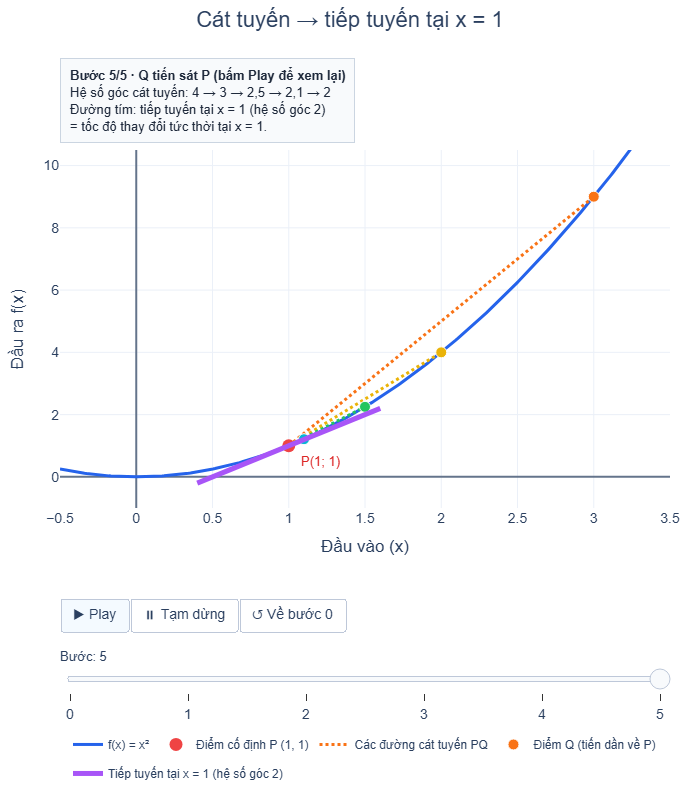

In [30]:
tangent_caption = r"""
Khi điểm thứ hai \(Q\) (các chấm màu cam, vàng, xanh lá, xanh lơ) tiến gần
điểm thứ nhất \(P\) (chấm đỏ tại \(x=1\)), <strong>hệ số góc của đường cát
tuyến</strong> tiến gần <strong>hệ số góc của đường tiếp tuyến</strong> màu
tím.

<br><br>

Với \(Q=(1+h,\,(1+h)^2)\), hệ số góc của cát tuyến \(PQ\) là:

\[
\frac{f(1+h)-f(1)}{h}=\frac{(1+h)^2-1}{h}=2+h
\]

Khi \(h\) càng nhỏ (\(2;\ 1;\ 0{,}5;\ 0{,}1;\ \dots\)), giá trị
này lần lượt là \(4;\ 3;\ 2{,}5;\ 2{,}1;\ \dots\) và tiến gần
\(2\):

\[
\lim_{h\to 0}(2+h)=2
\]

Hệ số góc của đường tiếp tuyến này biểu diễn
<strong>tốc độ thay đổi tức thời</strong> tại \(x=1\).

<br>

<strong>Cách dùng:</strong>

Bấm <strong>Play</strong> để xem animation: mỗi bước sẽ có lời giải thích
riêng phía trên biểu đồ. Bạn cũng có thể bấm <strong>Tạm dừng</strong>,
kéo <strong>thanh trượt</strong> để chọn bước, hoặc bấm
<strong>Về bước 0</strong> để bắt đầu lại.
"""


add_caption(
    fig=fig_tangent,

    caption=tangent_caption,

    title="Từ đường cát tuyến đến đường tiếp tuyến",

    html_name="secant_to_tangent_function.html"
)

# Xuất HTML biểu đồ animation

In [31]:
export_figure(
    fig=fig_tangent,

    filename="secant_to_tangent_function.html",

    caption=tangent_caption,

    caption_title="Từ đường cát tuyến đến đường tiếp tuyến",

    page_title="Cát tuyến và tiếp tuyến - AI From Scratch"
)

Exported successfully: D:\lh222k\ai-from-scratch\visualizations\secant_to_tangent_function.html
File size: 4737.80 KB


WindowsPath('D:/lh222k/ai-from-scratch/visualizations/secant_to_tangent_function.html')

# Tạo index.html

In [32]:
index_html = """<!DOCTYPE html>
<html lang="vi">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>AI From Scratch - Trực quan hoá hàm số</title>

    <style>

        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            padding: 40px 20px;

            font-family: Arial, sans-serif;

            background: #f8fafc;
            color: #1e293b;
        }

        .container {
            width: 100%;
            max-width: 900px;

            margin: 0 auto;
        }

        header {
            text-align: center;
            margin-bottom: 40px;
        }

        header h1 {
            font-size: 32px;
            margin-bottom: 10px;
        }

        header p {
            color: #64748b;
            line-height: 1.7;
        }

        .card {
            display: block;

            padding: 24px;
            margin-bottom: 20px;

            background: white;

            border: 1px solid #e2e8f0;
            border-radius: 12px;

            text-decoration: none;
            color: inherit;

            transition: transform 0.2s;
        }

        .card:hover {
            transform: translateY(-4px);
            border-color: #2563eb;
        }

        .card h2 {
            margin-top: 0;
            color: #2563eb;
        }

        .card p {
            color: #64748b;
            line-height: 1.6;
        }

        footer {
            margin-top: 40px;
            text-align: center;
            color: #94a3b8;
            font-size: 13px;
        }

        @media (max-width: 600px) {

            body {
                padding: 24px 14px;
            }

            header h1 {
                font-size: 25px;
            }

        }

    </style>

</head>

<body>

    <main class="container">

        <header>

            <h1>AI From Scratch</h1>

            <p>
                Các biểu đồ tương tác cho Toán học, Machine Learning và Deep Learning.
            </p>

        </header>


        <section>

            <a class="card"
               href="./linear_function.html">

                <h2>Hàm số bậc nhất</h2>

                <p>
                    Khám phá hàm số f(x) = 2x + 1: hệ số góc, tung độ gốc và tốc độ thay đổi không đổi.
                </p>

            </a>


            <a class="card"
               href="./quadratic_function.html">

                <h2>Hàm số bậc hai</h2>

                <p>
                    Khám phá hàm số g(x) = x&sup2;: đỉnh parabol, tính đối xứng và các điểm nổi bật.
                </p>

            </a>

            <a class="card"
               href="./limit_function.html">

                <h2>Giới hạn của hàm số</h2>

                <p>
                    Khám phá g(x) = (x&sup2; &minus; 1)/(x &minus; 1):
                    đường thẳng y = x + 1 bị loại bỏ điểm (1, 2)
                    và giới hạn khi x tiến đến 1.
                </p>

            </a>

            <a class="card"
               href="./limit_approach_function.html">

                <h2>Giới hạn khi x tiến đến 3</h2>

                <p>
                    Quan sát f(x) = 2x + 1: khi x tiến gần 3 từ bên trái
                    và bên phải, f(x) tiến gần 7.
                </p>

            </a>

            <a class="card"
               href="./secant_line_function.html">

                <h2>Đường cát tuyến</h2>

                <p>
                    Đường nối (1, 1) và (3, 9) trên đồ thị f(x) = x&sup2;:
                    hệ số góc chính là tốc độ thay đổi trung bình.
                </p>

            </a>

            <a class="card"
               href="./secant_to_tangent_function.html">

                <h2>Cát tuyến và tiếp tuyến (animation)</h2>

                <p>
                    Bấm Play: điểm Q tiến dần về P trên f(x) = x&sup2;,
                    cát tuyến xoay dần thành tiếp tuyến tại x = 1,
                    mỗi bước có lời giải thích riêng.
                </p>

            </a>

        </section>


        <footer>

            AI From Scratch - Tài liệu học tương tác<br>
            Công thức toán trên mỗi trang cần Internet (MathJax CDN).

        </footer>

    </main>

</body>

</html>
"""


index_path = VISUALIZATION_DIR / "index.html"

index_path.write_text(
    index_html,
    encoding="utf-8"
)

print("Homepage created:", index_path)

Homepage created: D:\lh222k\ai-from-scratch\visualizations\index.html


# Kiểm tra file đầu ra

Kiểm tra file tồn tại, có nội dung hợp lệ, và link trong `index.html` trỏ đúng file.

In [33]:
import re

expected_files = [
    "index.html",
    "linear_function.html",
    "quadratic_function.html",
    "limit_function.html",
    "limit_approach_function.html",
    "secant_line_function.html",
    "secant_to_tangent_function.html"
]


print("=" * 55)
print("VISUALIZATION EXPORT REPORT")
print("=" * 55)

all_ok = True

for filename in expected_files:

    file_path = VISUALIZATION_DIR / filename

    if file_path.exists():

        size_kb = file_path.stat().st_size / 1024

        print(f"[SUCCESS] {filename}")
        print(f"          Size: {size_kb:.2f} KB")

    else:

        all_ok = False
        print(f"[FAILED] {filename}")


# Content checks for the chart pages
for filename in ["linear_function.html", "quadratic_function.html", "limit_function.html", "limit_approach_function.html", "secant_line_function.html", "secant_to_tangent_function.html"]:

    text = (VISUALIZATION_DIR / filename).read_text(encoding="utf-8")

    checks = {
        "doctype": text.startswith("<!DOCTYPE html>"),
        "plotly.js embedded": "plotly.js" in text and len(text) > 1_000_000,
        "plot div": 'class="plotly-graph-div"' in text,
        "caption": 'class="visualization-caption"' in text,
        "MathJax": "mathjax@3" in text,
    }

    for name, ok in checks.items():

        all_ok = all_ok and ok
        print(f"  {filename}: {name:<20} {'OK' if ok else 'MISSING'}")


# Link checks for index.html
index_text = (VISUALIZATION_DIR / "index.html").read_text(encoding="utf-8")

for href in re.findall(r'href="([^"]+)"', index_text):

    target = (VISUALIZATION_DIR / href).resolve()
    ok = target.is_file()

    all_ok = all_ok and ok
    print(f"  index.html link {href:<28} {'OK' if ok else 'BROKEN'}")


print("=" * 55)
print("All checks passed." if all_ok else "Some checks FAILED.")

assert all_ok, "Export validation failed"

VISUALIZATION EXPORT REPORT
[SUCCESS] index.html
          Size: 4.61 KB
[SUCCESS] linear_function.html
          Size: 4723.32 KB
[SUCCESS] quadratic_function.html
          Size: 4726.36 KB
[SUCCESS] limit_function.html
          Size: 4730.03 KB
[SUCCESS] limit_approach_function.html
          Size: 4724.83 KB
[SUCCESS] secant_line_function.html
          Size: 4727.34 KB
[SUCCESS] secant_to_tangent_function.html
          Size: 4737.80 KB
  linear_function.html: doctype              OK
  linear_function.html: plotly.js embedded   OK
  linear_function.html: plot div             OK
  linear_function.html: caption              OK
  linear_function.html: MathJax              OK
  quadratic_function.html: doctype              OK
  quadratic_function.html: plotly.js embedded   OK
  quadratic_function.html: plot div             OK
  quadratic_function.html: caption              OK
  quadratic_function.html: MathJax              OK
  limit_function.html: doctype              OK
  limit_fun

# Mở trực quan hoá trên máy

Mở file HTML đã export bằng trình duyệt mặc định (an toàn hơn `IFrame` với đường dẫn tương đối, vốn phụ thuộc vào Jupyter server root). Đặt `OPEN_IN_BROWSER = True` để mở.

In [34]:
import webbrowser

OPEN_IN_BROWSER = False

index_uri = (VISUALIZATION_DIR / "index.html").as_uri()

print("Local preview:", index_uri)

if OPEN_IN_BROWSER:
    webbrowser.open(index_uri)

Local preview: file:///D:/lh222k/ai-from-scratch/visualizations/index.html
